# 03 - Analysis results

This notebook displays the saved model estimates and a descriptive child-asthma scatter plot for 2023, the latest year in the panel. The adult raw-rate robustness model is labeled in the adult panel.

The scatter is descriptive; this notebook does not calculate correlations or fit regressions.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

clean_dir = Path("data/clean")
if not clean_dir.is_dir():
    clean_dir = Path("../data/clean")

model_results = pd.read_csv(clean_dir / "model_results.csv")
panel = pd.read_csv(clean_dir / "uhf42_panel.csv")
print(f"Model rows: {len(model_results)} | Panel rows: {len(panel)}")

Model rows: 10 | Panel rows: 378


## PM2.5 coefficient estimates and 95% confidence intervals

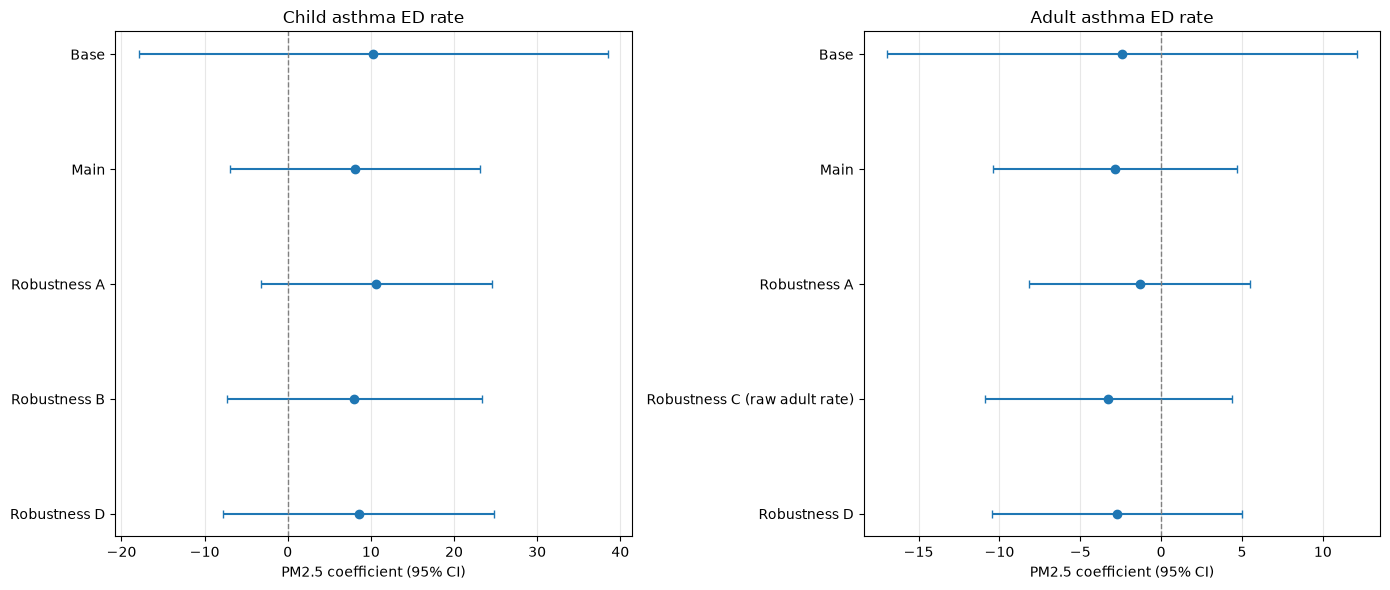

In [2]:
child_results = model_results.loc[
    model_results["outcome"].eq("asthma_child_rate")
].copy()
adult_results = model_results.loc[
    model_results["outcome"].isin(
        ["asthma_adult_rate_adj", "asthma_adult_rate_raw"]
    )
].copy()
adult_results["plot_label"] = adult_results["specification"]
adult_results.loc[
    adult_results["outcome"].eq("asthma_adult_rate_raw"), "plot_label"
] = "Robustness C (raw adult rate)"

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, results, title, labels in [
    (
        axes[0],
        child_results,
        "Child asthma ED rate",
        child_results["specification"],
    ),
    (
        axes[1],
        adult_results,
        "Adult asthma ED rate",
        adult_results["plot_label"],
    ),
]:
    positions = range(len(results))
    lower_error = results["coefficient"] - results["ci_lower_95"]
    upper_error = results["ci_upper_95"] - results["coefficient"]
    ax.errorbar(
        results["coefficient"],
        positions,
        xerr=[lower_error, upper_error],
        fmt="o",
        capsize=3,
    )
    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.set_yticks(list(positions), labels=labels)
    ax.invert_yaxis()
    ax.set_title(title)
    ax.set_xlabel("PM2.5 coefficient (95% CI)")
    ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
plt.show()

## PM2.5 and child asthma ED rate in 2023

Each point is one UHF42 neighborhood; color represents neighborhood poverty.

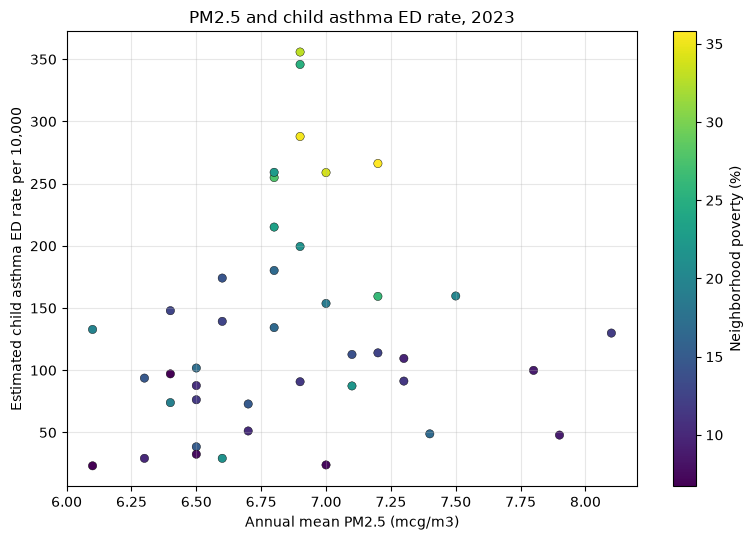

In [3]:
scatter_year = 2023
year_data = panel.loc[panel["year"].eq(scatter_year)]

fig, ax = plt.subplots(figsize=(8, 5.5))
points = ax.scatter(
    year_data["pm25_annual"],
    year_data["asthma_child_rate"],
    c=year_data["poverty_pct"],
    cmap="viridis",
    edgecolors="black",
    linewidths=0.3,
)
fig.colorbar(points, ax=ax, label="Neighborhood poverty (%)")
ax.set_title(f"PM2.5 and child asthma ED rate, {scatter_year}")
ax.set_xlabel("Annual mean PM2.5 (mcg/m3)")
ax.set_ylabel("Estimated child asthma ED rate per 10,000")
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()